In [ ]:
%load_ext autoreload
%autoreload 2
import torch
import torch.nn as nn
import os
import numpy as np

import matplotlib.pyplot as plt
import matplotlib as mpl

import wandb

from copy import deepcopy

from cmcrameri import cm


# Configure matplotlib to use LaTeX for r'' strings while keeping other text unchanged
mpl.rcParams.update({
    'text.usetex': True,          # Use LaTeX for r'' strings
    'font.family': 'sans-serif',  # Default font family for regular text
    'mathtext.fontset': 'dejavusans',  # Font for math not using r''
    'axes.formatter.use_mathtext': False  # Enable math text for tick labels
})

In [2]:
# set random seed
def set_seed(seed):
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    np.random.seed(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False
    os.environ['PYTHONHASHSEED'] = str(seed)
set_seed(42)

In [ ]:
from plot_utils import extract_all_results, results_to_dataframe, \
    plot_comparison, method_names, method_colors

from readout_utils import compute_pca_projection, compute_umap_projection

In [ ]:
from repl.networks.utils import additional_data_process, prepare_model
from repl.scripts.utils import (
    get_data_specs,
    prepare_data,
)

In [5]:
api = wandb.Api()

In [ ]:
savedir = 'RPL_figures/4_triplets'
if not os.path.exists(savedir):
    os.makedirs(savedir)

In [ ]:
datasets = ['mnist_triplets', 'mnist_triplets_feedforward', 'mnist_triplets_offline_enc']

dataset_to_plot = 'mnist_triplets'

method_map = {
    'sup': 'supervised',
    'rand': 'random',
    'pred': 'pred',
    'inv_sg': 'inv_sg',
}

# Extract results with both accuracy and r2 metrics
results = extract_all_results(datasets=datasets, method_map=method_map, wandb_project="RPL")

# Convert to DataFrame
results_df = results_to_dataframe(results)

Found 665 runs in the API
No exact match found for method_key: mul10_pred
No exact match found for method_key: mult10_pred_ctx_target
No exact match found for method_key: n_pred_ctx_target
No exact match found for method_key: n_inv_sg
No exact match found for method_key: n_random
No exact match found for method_key: n_supervised
No exact match found for method_key: n_pred_ctx_target
No exact match found for method_key: n_pred
No exact match found for method_key: n_offline_enc_pred
No exact match found for method_key: n_offline_enc_pred
No exact match found for method_key: n_offline_enc_pred
No exact match found for method_key: n_pred
No exact match found for method_key: n_pred
No exact match found for method_key: n_pred
No exact match found for method_key: offline_enc_random
No exact match found for method_key: offline_enc_supervised
No exact match found for method_key: offline_enc_inv_sg
No exact match found for method_key: offline_enc_inv_sg
No exact match found for method_key: offli

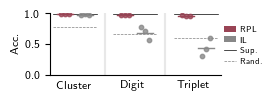

In [ ]:
fig, axs = plot_comparison(results_df, 
                    methods_to_plot=['pred', 'inv_sg'],
                    baseline_methods=['sup', 'rand'],
                    task_names={'digit_cluster': 'Cluster', 'digit': 'Digit', 'triplet': 'Triplet'},
                    method_names=method_names,
                    method_colors=method_colors,
                    figsize=(2.2, 0.8),
                    dataset='mnist_triplets',
                    ylim=(0.0, 1.0),
                    loc_legend=(1.0, 0.1),
                    display_legend=True,
                    legend_ax_idx=1,
                    point_size=10,
                    sharey=True)
fig.savefig(os.path.join(savedir, 'mnist_triplets_comparison.pdf'), bbox_inches='tight', transparent=True)

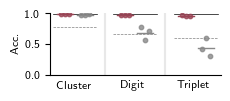

In [ ]:
fig, axs = plot_comparison(results_df, 
                    methods_to_plot=['pred', 'inv_sg'],
                    baseline_methods=['sup', 'rand'],
                    task_names={'digit_cluster': 'Cluster', 'digit': 'Digit', 'triplet': 'Triplet'},
                    method_names=method_names,
                    method_colors=method_colors,
                    figsize=(2.2, 0.8),
                    dataset='mnist_triplets',
                    ylim=(0.0, 1.0),
                    loc_legend=(1.0, 0.1),
                    display_legend=False,
                    legend_ax_idx=1,
                    point_size=10,
                    sharey=True)
fig.savefig(os.path.join(savedir, 'suppl_mnist_triplets_comparison.pdf'), bbox_inches='tight', transparent=True)

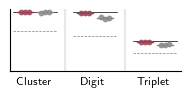

In [ ]:
fig, axs = plot_comparison(results_df, 
                    methods_to_plot=['pred', 'inv_sg'],
                    baseline_methods=['sup', 'rand'],
                    task_names={'digit_cluster': 'Cluster', 'digit': 'Digit', 'triplet': 'Triplet'},
                    method_names=method_names,
                    method_colors=method_colors,
                    figsize=(2.2, 0.8),
                    dataset='mnist_triplets_offline_enc',
                    ylim=(0.0, 1.0),
                    loc_legend=(1.0, 0.1),
                    display_legend=False,
                    display_yticks=False,
                    legend_ax_idx=1,
                    point_size=10,
                    sharey=True)
fig.savefig(os.path.join(savedir, 'suppl_mnist_triplets_enc_comparison.pdf'), bbox_inches='tight', transparent=True)

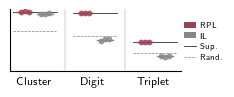

In [11]:
fig, axs = plot_comparison(results_df, 
                    methods_to_plot=['pred', 'inv_sg'],
                    baseline_methods=['sup', 'rand'],
                    task_names={'digit_cluster': 'Cluster', 'digit': 'Digit', 'triplet': 'Triplet'},
                    method_names=method_names,
                    method_colors=method_colors,
                    figsize=(2.2, 0.8),
                    dataset='mnist_triplets_feedforward',
                    ylim=(0.0, 1.0),
                    loc_legend=(1.0, 0.1),
                    display_legend=True,
                    display_yticks=False,
                    legend_ax_idx=1,
                    point_size=10,
                    sharey=True)
fig.savefig(os.path.join(savedir, 'suppl_mnist_triplets_ff_comparison.pdf'), bbox_inches='tight', transparent=True)

In [12]:
input_size, num_classes = get_data_specs(dataset="mnist",
                                        target_label="multitask",
                                        mnist_seqtype="triplets",
                                        flatten_images=True)

(train_loader, train_sampler, 
    val_loader, val_sampler,
        test_loader, test_sampler,
    ) = prepare_data(
            dataset="mnist",
            data_input_dir="../datasets",
            seq_len=128,
            batch_size=32,
            val_batch_size=64,
            grayscale=True,
            target_label="multitask",
            mnist_seqtype="triplets",
            num_sequences=5000,
        )

In [ ]:
preprocess, postprocess = additional_data_process("mnist")
n_in_channels = 1

inv_model = deepcopy(prepare_model(
    encoder_kind="mlp",
    integrator_kind="rnn",
    predictor_kind="mlp",
    input_size=input_size,
    pred_n_hidden_layers=1,
    enc_dim=32,
    ctx_dim=128,
    prediction_target="enc",
    use_bn_enc=True,
    enc_n_layers=2,
    enc_kernel_size=[(3, 3)] * 3,
    enc_stride=[(1, 1)] * 3,
    enc_padding=[(1, 1)] * 3,
    preprocess=preprocess,
    postprocess=postprocess,
    n_in_channels=n_in_channels,
    pred_hidden_dim=128,
    pred_steps=1,
    state_dict=torch.load('../checkpoints/mnist_triplets_inv_sg_1/model_final.pt')
))

pred_model = deepcopy(prepare_model(
    encoder_kind="mlp",
    integrator_kind="rnn",
    predictor_kind="mlp",
    input_size=input_size,
    pred_n_hidden_layers=1,
    enc_dim=32,
    ctx_dim=128,
    prediction_target="enc",
    use_bn_enc=True,
    enc_n_layers=2,
    enc_kernel_size=[(3, 3)] * 3,
    enc_stride=[(1, 1)] * 3,
    enc_padding=[(1, 1)] * 3,
    preprocess=preprocess,
    postprocess=postprocess,
    n_in_channels=n_in_channels,
    pred_hidden_dim=128,
    pred_steps=1,
    state_dict=torch.load('../checkpoints/mnist_triplets_pred_1/model_final.pt')
))

inv_ff_model = deepcopy(prepare_model(
    encoder_kind="mlp",
    integrator_kind="identity",
    predictor_kind="mlp",
    input_size=input_size,
    pred_n_hidden_layers=1,
    enc_dim=32,
    ctx_dim=128,
    prediction_target="enc",
    use_bn_enc=True,
    enc_n_layers=2,
    enc_kernel_size=[(3, 3)] * 3,
    enc_stride=[(1, 1)] * 3,
    enc_padding=[(1, 1)] * 3,
    preprocess=preprocess,
    postprocess=postprocess,
    n_in_channels=n_in_channels,
    pred_hidden_dim=128,
    pred_steps=1,
    state_dict=torch.load('../checkpoints/mnist_triplets_feedforward_inv_sg_1/model_final.pt')
))

pred_ff_model = deepcopy(prepare_model(
    encoder_kind="mlp",
    integrator_kind="identity",
    predictor_kind="mlp",
    input_size=input_size,
    pred_n_hidden_layers=1,
    enc_dim=32,
    ctx_dim=128,
    prediction_target="enc",
    use_bn_enc=True,
    enc_n_layers=2,
    enc_kernel_size=[(3, 3)] * 3,
    enc_stride=[(1, 1)] * 3,
    enc_padding=[(1, 1)] * 3,
    preprocess=preprocess,
    postprocess=postprocess,
    n_in_channels=n_in_channels,
    pred_hidden_dim=128,
    pred_steps=1,
    state_dict=torch.load('../checkpoints/mnist_triplets_feedforward_pred_1/model_final.pt')
))


In [ ]:
# Set the models to evaluation mode, pass the validation data through the models, and record the outputs
inv_model.eval()
pred_model.eval()
# pred_ctx_target_model.eval()

inv_ctxs = []
inv_zs = []

inv_ff_zs = []

pred_ctxs = []
pred_zs = []

pred_ff_zs = []

# pred_ctx_target_zs = []
# pred_ctx_target_ctxs = []

labels = []

for data, target in test_loader:
    labels.append(target[1])

    z, proj, _ = inv_model(data)
    inv_zs.append(z)
    inv_ctxs.append(proj)

    z, proj, _ = pred_model(data)
    pred_zs.append(z)
    pred_ctxs.append(proj)

    # z, proj, _ = pred_ctx_target_model(data)
    # pred_ctx_target_zs.append(z)
    # pred_ctx_target_ctxs.append(proj)

    z, proj, _ = inv_ff_model(data)
    inv_ff_zs.append(z)

    z, proj, _ = pred_ff_model(data)
    pred_ff_zs.append(z)

inv_zs = torch.cat(inv_zs, dim=0)
inv_ctxs = torch.cat(inv_ctxs, dim=0)
inv_zs = inv_zs.view(-1, inv_zs.size(-1))
inv_ctxs = inv_ctxs.view(-1, inv_ctxs.size(-1))

inv_ff_zs = torch.cat(inv_ff_zs, dim=0)
inv_ff_zs = inv_ff_zs.view(-1, inv_ff_zs.size(-1))

pred_zs = torch.cat(pred_zs, dim=0)
pred_ctxs = torch.cat(pred_ctxs, dim=0)
pred_zs = pred_zs.view(-1, pred_zs.size(-1))
pred_ctxs = pred_ctxs.view(-1, pred_ctxs.size(-1))

pred_ff_zs = torch.cat(pred_ff_zs, dim=0)
pred_ff_zs = pred_ff_zs.view(-1, pred_ff_zs.size(-1))

labels = torch.cat(labels, dim=0)
labels = labels.view(-1, labels.size(-1))

In [15]:
z.shape, proj.shape, pred_ctxs.shape, data.shape

(torch.Size([64, 128, 32]),
 torch.Size([64, 128, 32]),
 torch.Size([638976, 128]),
 torch.Size([64, 128, 1, 28, 28]))

In [ ]:
mode = 'pca'
if mode == 'pca':
    inv_z_results = compute_pca_projection(inv_zs.detach().numpy(), n_components=10)
    inv_ctx_results = compute_pca_projection(inv_ctxs.detach().numpy(), n_components=10)

    inv_ff_z_results = compute_pca_projection(inv_ff_zs.detach().numpy(), n_components=10)

    pred_z_results = compute_pca_projection(pred_zs.detach().numpy(), n_components=10)
    pred_ctx_results = compute_pca_projection(pred_ctxs.detach().numpy(), n_components=10)

    pred_ff_z_results = compute_pca_projection(pred_ff_zs.detach().numpy(), n_components=10)

    print("Invariance context PCA explained variance:", inv_ctx_results['explained_variance_ratio'])
    print("Prediction context PCA explained variance:", pred_ctx_results['explained_variance_ratio'])
    print("Invariance encoder PCA explained variance:", inv_z_results['explained_variance_ratio'])
    print("Prediction encoder PCA explained variance:", pred_z_results['explained_variance_ratio'])
elif mode == 'umap':
    # subsample data for faster computation
    n_samples, n_features = inv_ctxs.shape
    if n_samples > 100000:
        print("Subsampling data for faster computation")
        idx = np.random.choice(n_samples, 100000, replace=False)
        inv_ctxs = inv_ctxs[idx]
        pred_ctxs = pred_ctxs[idx]
        inv_zs = inv_zs[idx]
        pred_zs = pred_zs[idx]
        labels = labels[idx]
    inv_ctx_results = compute_umap_projection(inv_ctxs.detach().numpy(), n_components=6, n_neighbors=20, min_dist=0.5, metric='cosine', densmap=True)
    pred_ctx_results = compute_umap_projection(pred_ctxs.detach().numpy(), n_components=6, n_neighbors=20, min_dist=0.5, metric='cosine', densmap=True)
    inv_z_results = compute_umap_projection(inv_zs.detach().numpy(), n_components=6, n_neighbors=20, min_dist=0.5, metric='cosine', densmap=True)
    pred_z_results = compute_umap_projection(pred_zs.detach().numpy(), n_components=6, n_neighbors=20, min_dist=0.5, metric='cosine', densmap=True)

Invariance context PCA explained variance: [0.25345042 0.18418391 0.17413712 0.10063652 0.0362342  0.02626856
 0.02174915 0.01881664 0.01682946 0.01314297]
Prediction context PCA explained variance: [0.21976495 0.16227199 0.11939207 0.10144409 0.05548414 0.04964975
 0.03534591 0.02722649 0.02333249 0.0191515 ]
Invariance encoder PCA explained variance: [0.25827375 0.2424241  0.17026642 0.12709531 0.05300543 0.03095945
 0.02577966 0.01387586 0.01067443 0.00932591]
Prediction encoder PCA explained variance: [0.21185327 0.17063513 0.14812699 0.10365247 0.07830642 0.07388487
 0.04356539 0.02818148 0.01773125 0.01490757]


In [ ]:
colormap = cm.managua
colormap2 = cm.lipari
colormap3 = cm.berlin

digit_colormap = colormap3.resampled(9)  # 10 colors for digits 0-9
cluster_colormap = colormap.resampled(3)  # 4 colors for clusters 0-3
triplet_colormap_full = colormap.resampled(18)  # 18 colors for triplets 0-17
triplet_colormap = colormap2.resampled(6)  # 6 colors for triplets 0-5
triplet_pos_colormap = colormap2.resampled(4)  # 3 colors for triplet positions 0-2, we're going to skip the last one for better visualization

# Convert colormaps to lists of colors
digit_colormap = [digit_colormap(i) for i in range(9)]
cluster_colormap = [cluster_colormap(i) for i in range(3)]
triplet_colormap_full = [triplet_colormap_full(i) for i in range(18)]
triplet_colormap = [triplet_colormap(i) for i in range(6)]
triplet_pos_colormap = [triplet_pos_colormap(i) for i in range(3)]

# Define color dictionary for the labels
digit_colors = {
    # Digits 0-9 in their respective colors from the colormap
    0: '#ABABAB',  # gray for digit 0
    1: digit_colormap[0],
    2: digit_colormap[1],
    3: digit_colormap[2],
    4: digit_colormap[3],
    5: digit_colormap[4],
    6: digit_colormap[5],
    7: digit_colormap[6],
    8: digit_colormap[7],
    9: digit_colormap[8]
}

cluster_colors = {
    # Clusters 0-3 in their respective colors from the colormap
    0: '#ABABAB',  # gray for cluster 0
    1: digit_colormap[1],
    2: digit_colormap[4],
    3: digit_colormap[7]
}

triplet_colors_full = {
    # Triplets 0-17 in their respective colors from the colormap
    0: triplet_colormap_full[0],
    1: triplet_colormap_full[1],
    2: triplet_colormap_full[2],
    3: triplet_colormap_full[3],
    4: triplet_colormap_full[4],
    5: triplet_colormap_full[5],

    6: triplet_colormap_full[6],
    7: triplet_colormap_full[7],
    8: triplet_colormap_full[8],
    9: triplet_colormap_full[9],
    10: triplet_colormap_full[10],
    11: triplet_colormap_full[11],

    12: triplet_colormap_full[12],
    13: triplet_colormap_full[13],
    14: triplet_colormap_full[14],
    15: triplet_colormap_full[15],
    16: triplet_colormap_full[16],
    17: triplet_colormap_full[17]
}

triplet_colors = {
    # # Invalid data points in gray
    -1: '#ABABAB',  # gray for invalid triplet data points

    0: triplet_colormap[0],
    1: triplet_colormap[1],
    2: triplet_colormap[2],
    3: triplet_colormap[3],
    4: triplet_colormap[4],
    5: triplet_colormap[5],

    6: triplet_colormap[0],
    7: triplet_colormap[1],
    8: triplet_colormap[2],
    9: triplet_colormap[3],
    10: triplet_colormap[4],
    11: triplet_colormap[5],

    12: triplet_colormap[0],
    13: triplet_colormap[1],
    14: triplet_colormap[2],
    15: triplet_colormap[3],
    16: triplet_colormap[4],
    17: triplet_colormap[5]
}

triplet_pos_colors = {
    -1: '#ABABAB',  # gray for invalid triplet data points
    0: triplet_pos_colormap[0],
    1: triplet_pos_colormap[1],
    2: triplet_pos_colormap[2]
}

In [ ]:
def plot_pca_projection_2d(projections, labels, colors, title=None, ax=None, legend=False, components=(0,1), point_size=0.5, alpha=0.5, max_pts_per_class=200, proportional_sampling=False, legend_labels=None, lgd_ncol=1):
    """
    Plot PCA projections in 2D.
    
    Args:
        projections: numpy array of shape (n_samples, n_components)
        labels: numpy array of shape (n_samples,)
        title: title for the plot
        ax: matplotlib axis to use for plotting (default: None)
        legend: whether to show legend (default: False)
        components: tuple of two integers indicating which components to plot (default: (0,1))
        point_size: size of the points in the scatter plot (default: 0.5)
        alpha: transparency of the points (default: 0.5)
        max_pts_per_class: maximum number of points to plot per class (default: 200)
        proportional_sampling: whether to sample points proportionally to their class size (default: False)
    """
    if ax is None:
        fig, ax = plt.subplots(figsize=(1, 1))
    
    # Plot each class separately with predefined colors
    num_unique_classes = len(np.unique(labels))
    for label in np.unique(labels):
        idx = labels == label
        subset_projections = projections[idx]
        
        # Subsample if too many points
        if subset_projections.shape[0] > max_pts_per_class:
            if proportional_sampling:
                # Ignore max_pts_per_class and sample proportionally
                num_pts = int(max_pts_per_class * subset_projections.shape[0] / projections.shape[0])
                subset_projections = subset_projections[
                    np.random.choice(subset_projections.shape[0], num_pts, replace=False)]
            else:
                # Uniform sampling
                subset_projections = subset_projections[
                    np.random.choice(subset_projections.shape[0], max_pts_per_class, replace=False)]
        
        ax.scatter(subset_projections[:, components[0]], 
                  subset_projections[:, components[1]], 
                  label=legend_labels[label] if legend_labels else label,
                  color=colors[label],
                  alpha=alpha,
                  s=point_size)
    
    if title:
        ax.set_title(title, fontsize=8)

    ax.set_xticks([])
    ax.set_yticks([])
    # turn off axis lines
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['bottom'].set_visible(False)
    ax.spines['left'].set_visible(False)
    
    if legend:
        leg = ax.legend(
        loc=(1.0, 0.0),
        ncol=lgd_ncol,
        fontsize=6,
        frameon=False,
        markerscale=2.0,
        columnspacing=0.5,
        handletextpad=-0.05)
        # Set legend markers to full opacity
        for handle in leg.legend_handles:
            handle.set_alpha(1.0)
    
    return ax

In [19]:
colors_digits = digit_colors
# exclude the gray color for digit 0
colors_digits = {k: v for k, v in colors_digits.items() if k != 0}

# print hex code from the rgba color
def rgba_to_hex(rgba):
    return '#{:02x}{:02x}{:02x}'.format(
        int(rgba[0] * 255),
        int(rgba[1] * 255),
        int(rgba[2] * 255),
    )

# Convert the colors to hex format
colors_digits_hex = {k: rgba_to_hex(v) for k, v in colors_digits.items()}
print("Digit colors in hex format:")
for k, v in colors_digits_hex.items():
    print(f"{k}: {v}")

Digit colors in hex format:
1: #ffcf67
2: #d79252
3: #b06142
4: #803839
5: #562949
6: #4b4680
7: #5776b4
8: #6babda
9: #80e7fe


In [20]:
def plot_pca_comparison_grid(pred_results, inv_results, labels, colors, n_components=3, 
                           figsize=(4.5, 3.0), point_size=5.0, alpha=0.3, legend=False, legend_labels=None,
                           max_pts_per_class=50, filename=None, savedir=None, proportional_sampling=False,
                           legend_ncol=1):
    """
    Plot PCA projections for two methods in a 2x3 grid showing different component pairs.
    
    Args:
        pred_results: PCA results dictionary for prediction method (with 'projections' key)
        inv_results: PCA results dictionary for invariance method (with 'projections' key)
        labels: numpy array of labels for coloring points
        colors: dictionary mapping labels to colors
        n_components: number of component pairs to plot (default: 3, plots pairs (0,1), (2,3), (4,5))
        figsize: tuple of figure size (default: (4.5, 3.0))
        point_size: size of scatter points (default: 5.0)
        alpha: transparency of points (default: 0.3)
        max_pts_per_class: maximum points per class to plot (default: 50)
        filename: name of file to save (without extension)
        savedir: directory to save figure in
        proportional_sampling: whether to sample points proportionally to their class size (default: False)
        legend: whether to show legend (default: False)
        legend_labels: labels for the legend (default: None, uses numeric labels)
        legend_ncol: number of columns in the legend (default: 1)
    
    Returns:
        fig: matplotlib figure object
    """
    fig = plt.figure(figsize=figsize)
    
    # First row - Prediction method
    for i in range(n_components):
        ax = fig.add_subplot(2, n_components, i + 1)
        components = (i*2, i*2 + 1)
        show_legend = (i == n_components - 1) and legend
        plot_pca_projection_2d(pred_results['projections'], labels, colors, 
                              ax=ax, components=components, 
                              point_size=point_size, alpha=alpha, 
                              max_pts_per_class=max_pts_per_class,
                              proportional_sampling=proportional_sampling,
                              legend=show_legend, legend_labels=legend_labels,
                              lgd_ncol=legend_ncol)
    
    # Second row - Invariance method  
    for i in range(n_components):
        ax = fig.add_subplot(2, n_components, n_components + i + 1)
        components = (i*2, i*2 + 1)
        plot_pca_projection_2d(inv_results['projections'], labels, colors,
                              ax=ax, components=components,
                              point_size=point_size, alpha=alpha,
                              max_pts_per_class=max_pts_per_class,
                              proportional_sampling=proportional_sampling,
                              legend=False)

    # Add spacing between subplots
    fig.subplots_adjust(hspace=0.3)
    
    # Save figure if filename and savedir are provided
    if filename and savedir:
        fig.savefig(os.path.join(savedir, filename), bbox_inches='tight', 
                   transparent=True, dpi=300)
    
    return fig

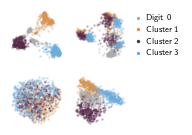

In [21]:
# Ctx projections colored by cluster
fig = plot_pca_comparison_grid(
    pred_results=pred_ctx_results,
    inv_results=inv_ctx_results, 
    labels=labels[:, 1],
    colors=cluster_colors,
    n_components=2,
    figsize=(1.5, 1.5),
    point_size=0.5,
    alpha=0.3,
    max_pts_per_class=300,
    filename='mnist_triplets_ctx_{}_projection_cluster.png'.format(mode),
    savedir=savedir,
    legend=True,
    legend_labels={
        0: 'Digit 0',
        1: 'Cluster 1',
        2: 'Cluster 2',
        3: 'Cluster 3'
    }
)

In [22]:
# Create new labels for distance since last 0 digit label (modulo 3), basically position in the triplet, 0 digit is labeled -1
digit_labels = labels[:, 0]
triplet_pos_labels = torch.ones_like(digit_labels) * -1

last_zero_idx = 0
for i in range(len(digit_labels)):
    if digit_labels[i] == 0:
        last_zero_idx = i
    else:
        triplet_pos_labels[i] = (i - last_zero_idx) % 3

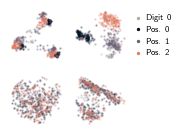

In [23]:
# Ctx projections colored by triplet position
fig = plot_pca_comparison_grid(
    pred_results=pred_ctx_results,
    inv_results=inv_ctx_results,
    labels=triplet_pos_labels,
    colors=triplet_pos_colors,
    n_components=2,
    figsize=(1.5, 1.5),
    point_size=0.5,
    alpha=0.3,
    max_pts_per_class=500,
    filename='mnist_triplets_ctx_{}_projection_triplet_pos.png'.format(mode),
    savedir=savedir,
    proportional_sampling=True,
    legend=True,
    legend_labels={
        -1: 'Digit 0',
        0: 'Pos. 0',
        1: 'Pos. 1',
        2: 'Pos. 2'
    }
)

### Supplementary Figure - Feedforward comparison

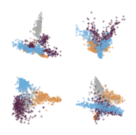

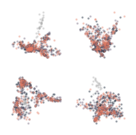

In [24]:
# z projections colored by cluster
fig = plot_pca_comparison_grid(
    pred_results=pred_z_results,
    inv_results=inv_z_results, 
    labels=labels[:, 1],
    colors=cluster_colors,
    n_components=2,
    figsize=(1.5, 1.5),
    point_size=0.5,
    alpha=0.3,
    max_pts_per_class=300,
    filename='mnist_triplets_z_{}_projection_cluster.png'.format(mode),
    savedir=savedir,
    legend=False,
    legend_labels={
        0: 'Digit 0',
        1: 'Cluster 1',
        2: 'Cluster 2',
        3: 'Cluster 3'
    }
)

# z projections colored by triplet position
fig = plot_pca_comparison_grid(
    pred_results=pred_z_results,
    inv_results=inv_z_results,
    labels=triplet_pos_labels,
    colors=triplet_pos_colors,
    n_components=2,
    figsize=(1.5, 1.5),
    point_size=0.5,
    alpha=0.3,
    max_pts_per_class=500,
    filename='mnist_triplets_z_{}_projection_triplet_pos.png'.format(mode),
    savedir=savedir,
    proportional_sampling=True,
    legend=False,
    legend_labels={
        -1: 'Digit 0',
        0: 'Pos. 0',
        1: 'Pos. 1',
        2: 'Pos. 2'
    }
)

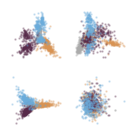

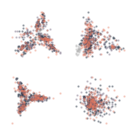

In [25]:
# z projections colored by cluster
fig = plot_pca_comparison_grid(
    pred_results=pred_ff_z_results,
    inv_results=inv_ff_z_results, 
    labels=labels[:, 1],
    colors=cluster_colors,
    n_components=2,
    figsize=(1.5, 1.5),
    point_size=0.5,
    alpha=0.3,
    max_pts_per_class=300,
    filename='mnist_triplets_ff_z_{}_projection_cluster.png'.format(mode),
    savedir=savedir,
    legend=False,
    legend_labels={
        0: 'Digit 0',
        1: 'Cluster 1',
        2: 'Cluster 2',
        3: 'Cluster 3'
    }
)

# z projections colored by triplet position
fig = plot_pca_comparison_grid(
    pred_results=pred_ff_z_results,
    inv_results=inv_ff_z_results,
    labels=triplet_pos_labels,
    colors=triplet_pos_colors,
    n_components=2,
    figsize=(1.5, 1.5),
    point_size=0.5,
    alpha=0.3,
    max_pts_per_class=500,
    filename='mnist_triplets_ff_z_{}_projection_triplet_pos.png'.format(mode),
    savedir=savedir,
    proportional_sampling=True,
    legend=False,
    legend_labels={
        -1: 'Digit 0',
        0: 'Pos. 0',
        1: 'Pos. 1',
        2: 'Pos. 2'
    }
)

### Supplementary Figure - Full set of projections

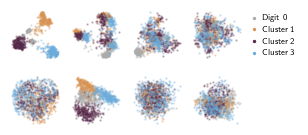

In [26]:
# Ctx projections colored by cluster
fig = plot_pca_comparison_grid(
    pred_results=pred_ctx_results,
    inv_results=inv_ctx_results, 
    labels=labels[:, 1],
    colors=cluster_colors,
    n_components=4,
    figsize=(3.0, 1.5),
    point_size=0.5,
    alpha=0.3,
    max_pts_per_class=300,
    filename='mnist_triplets_ctx_{}_projection_cluster_full.png'.format(mode),
    savedir=savedir,
    legend=True,
    legend_labels={
        0: 'Digit 0',
        1: 'Cluster 1',
        2: 'Cluster 2',
        3: 'Cluster 3'
    }
)

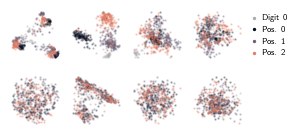

In [27]:
# Ctx projections colored by triplet position
fig = plot_pca_comparison_grid(
    pred_results=pred_ctx_results,
    inv_results=inv_ctx_results,
    labels=triplet_pos_labels,
    colors=triplet_pos_colors,
    n_components=4,
    figsize=(3.0, 1.5),
    point_size=0.5,
    alpha=0.3,
    max_pts_per_class=500,
    filename='mnist_triplets_ctx_{}_projection_triplet_pos_full.png'.format(mode),
    savedir=savedir,
    proportional_sampling=True,
    legend=True,
    legend_labels={
        -1: 'Digit 0',
        0: 'Pos. 0',
        1: 'Pos. 1',
        2: 'Pos. 2'
    }
)

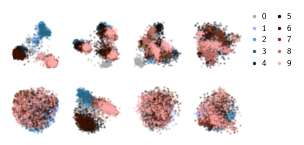

In [51]:
# Ctx projections colored by digit
fig = plot_pca_comparison_grid(
    pred_results=pred_ctx_results,
    inv_results=inv_ctx_results, 
    labels=labels[:, 0],
    colors=digit_colors,
    n_components=4,
    figsize=(3.0, 1.5),
    point_size=0.5,
    alpha=0.3,
    max_pts_per_class=300,
    filename='mnist_triplets_ctx_{}_projection_digit_full.png'.format(mode),
    savedir=savedir,
    legend=True,
    legend_ncol=2,
    # legend_labels={
    #     0: 'Digit 0',
    #     1: 'Cluster 1',
    #     2: 'Cluster 2',
    #     3: 'Cluster 3'
    # }
)

In [22]:
# filter out elements in the projections that are -1

pred_ctx_triplet_results = {
    'projections': pred_ctx_results['projections'][labels[:, 2] != -1],
    'explained_variance_ratio': pred_ctx_results['explained_variance_ratio'],
}

inv_ctx_triplet_results = {
    'projections': inv_ctx_results['projections'][labels[:, 2] != -1],
    'explained_variance_ratio': inv_ctx_results['explained_variance_ratio'],
}

triplet_filtered_labels = labels[labels[:, 2] != -1][:, 2]

In [23]:
triplet_colors[-1] = '#ABABAB'  # gray for invalid triplet data points

In [24]:
pred_ctx_triplet_results = pred_ctx_results
inv_ctx_triplet_results = inv_ctx_results
triplet_filtered_labels = labels[:, 2]

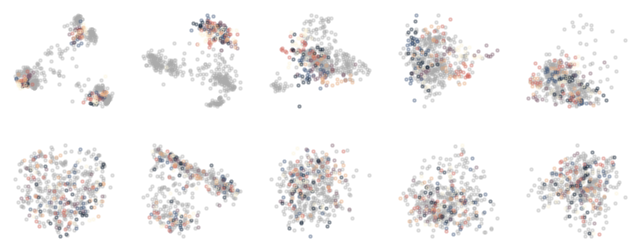

In [25]:
# Ctx projections colored by triplet
fig = plot_pca_comparison_grid(
    pred_results=pred_ctx_triplet_results,
    inv_results=inv_ctx_triplet_results,
    labels=triplet_filtered_labels,
    colors=triplet_colors,
    n_components=5,
    figsize=(8., 3.0),
    point_size=0.1 * 50,
    alpha=0.3,
    max_pts_per_class=500,
    filename='mnist_triplets_ctx_{}_projection.png'.format(mode),
    savedir=savedir,
    proportional_sampling=True
)

In [26]:
digit_labels, triplet_pos_labels

(tensor([5, 4, 6,  ..., 4, 5, 5]), tensor([0, 1, 2,  ..., 2, 0, 1]))

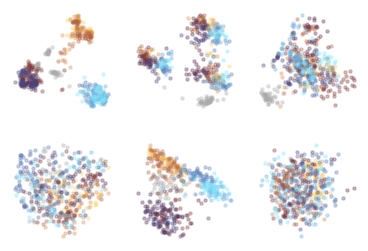

In [27]:
# Ctx projections colored by digit
fig = plot_pca_comparison_grid(
    pred_results=pred_ctx_results,
    inv_results=inv_ctx_results, 
    labels=labels[:, 0],
    colors=digit_colors,
    n_components=3,
    figsize=(4.5, 3.0),
    point_size=0.1 * 50,
    alpha=0.3,
    max_pts_per_class=50,
    filename='mnist_triplets_ctx_{}_projection.png'.format(mode),
    savedir=savedir
)

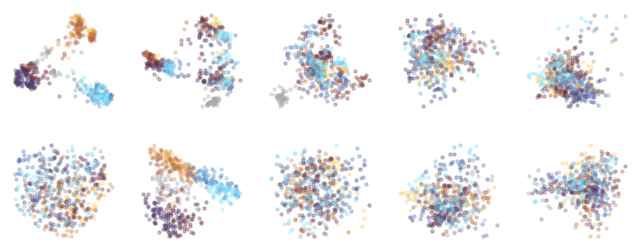

In [28]:
fig = plot_pca_comparison_grid(
    pred_results=pred_ctx_results,
    inv_results=inv_ctx_results, 
    labels=labels[:, 0],
    colors=digit_colors,
    n_components=5,
    figsize=(8.0, 3.0),
    point_size=0.1 * 50,
    alpha=0.3,
    max_pts_per_class=50,
    filename='mnist_triplets_ctx_{}_projection.png'.format(mode),
    savedir=savedir
)

In [29]:
cluster_to_plot = 3

# Create results dictionaries for the specific cluster

pred_ctx_cluster_results = {
    'projections': pred_ctx_results['projections'][labels[:, 1] == cluster_to_plot],
    'explained_variance_ratio': pred_ctx_results['explained_variance_ratio']
}

pred_z_cluster_results = {
    'projections': pred_z_results['projections'][labels[:, 1] == cluster_to_plot],
    'explained_variance_ratio': pred_z_results['explained_variance_ratio']
}

inv_ctx_cluster_results = {
    'projections': inv_ctx_results['projections'][labels[:, 1] == cluster_to_plot],
    'explained_variance_ratio': inv_ctx_results['explained_variance_ratio']
}

inv_z_cluster_results = {
    'projections': inv_z_results['projections'][labels[:, 1] == cluster_to_plot],
    'explained_variance_ratio': inv_z_results['explained_variance_ratio']
}

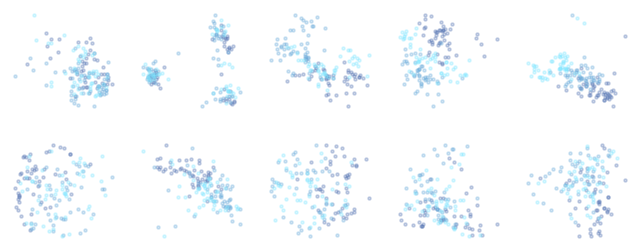

In [30]:
# Example usage:
fig = plot_pca_comparison_grid(
    pred_results=pred_ctx_cluster_results,
    inv_results=inv_ctx_cluster_results, 
    labels=labels[labels[:, 1] == cluster_to_plot, 0],
    colors=colors_digits,
    n_components=5,
    figsize=(8.0, 3.0),
    point_size=0.1 * 50,
    alpha=0.3,
    max_pts_per_class=50,
    filename='mnist_triplets_ctx_{}_projection.png'.format(mode),
    savedir=savedir
)

KeyError: 0

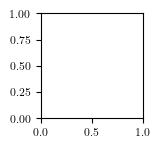

In [31]:
# Example usage:
fig = plot_pca_comparison_grid(
    pred_results=pred_ctx_results,
    inv_results=inv_ctx_results, 
    labels=labels[:, 0],
    colors=colors_digits,
    n_components=3,
    figsize=(4.5, 3.0),
    point_size=0.1 * 50,
    alpha=0.3,
    max_pts_per_class=50,
    filename='mnist_triplets_ctx_{}_projection.png'.format(mode),
    savedir=savedir
)

<Axes: >

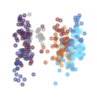

In [ ]:
plot_pca_projection_2d(pred_ctx_results['projections'], labels[:, 0], colors_digits, legend=False, components=(0,7), point_size=point_size, alpha=alpha, max_pts_per_class=max_pts_per_class)

<Axes: >

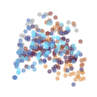

In [ ]:
plot_pca_projection_2d(inv_ctx_results['projections'], labels[:, 0], colors_digits, legend=False, components=(0,6), point_size=point_size, alpha=alpha, max_pts_per_class=max_pts_per_class)

In [ ]:
pred_ctx_results['explained_variance_ratio'], inv_ctx_results['explained_variance_ratio']

(array([0.21976495, 0.16227199, 0.11939207, 0.10144409, 0.05548414,
        0.04964975, 0.03534591, 0.02722649, 0.02333249, 0.0191515 ],
       dtype=float32),
 array([0.25345042, 0.18418391, 0.17413712, 0.10063652, 0.0362342 ,
        0.02626856, 0.02174915, 0.01881664, 0.01682946, 0.01314297],
       dtype=float32))

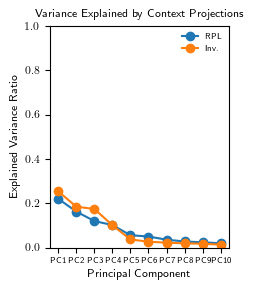

In [ ]:
# plot variance explained ratio
fig, ax = plt.subplots(figsize=(2.5, 3.0))
ax.plot(pred_ctx_results['explained_variance_ratio'], label='RPL', color='#1f77b4', marker='o')
ax.plot(inv_ctx_results['explained_variance_ratio'], label='Inv.', color='#ff7f0e', marker='o')
ax.set_xlabel('Principal Component', fontsize=8)
ax.set_ylabel('Explained Variance Ratio', fontsize=8)
ax.set_title('Variance Explained by Context Projections', fontsize=8)
ax.tick_params(axis='both', labelsize=8)
ax.legend(loc='upper right', fontsize=6, frameon=False)
ax.set_xticks(range(len(pred_ctx_results['explained_variance_ratio'])))
ax.set_xticklabels([f'PC{i+1}' for i in range(len(pred_ctx_results['explained_variance_ratio']))], fontsize=6)
ax.set_ylim(0, 1)
fig.tight_layout()

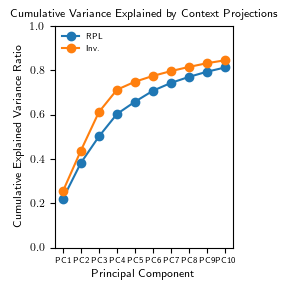

In [ ]:
# plot cumulative variance explained ratio
fig, ax = plt.subplots(figsize=(2.5, 3.0))
ax.plot(np.cumsum(pred_ctx_results['explained_variance_ratio']), label='RPL', color='#1f77b4', marker='o')
ax.plot(np.cumsum(inv_ctx_results['explained_variance_ratio']), label='Inv.', color='#ff7f0e', marker='o')
ax.set_xlabel('Principal Component', fontsize=8)
ax.set_ylabel('Cumulative Explained Variance Ratio', fontsize=8)
ax.set_title('Cumulative Variance Explained by Context Projections', fontsize=8)
ax.tick_params(axis='both', labelsize=8)
ax.legend(loc='upper left', fontsize=6, frameon=False)
ax.set_xticks(range(len(pred_ctx_results['explained_variance_ratio'])))
ax.set_xticklabels([f'PC{i+1}' for i in range(len(pred_ctx_results['explained_variance_ratio']))], fontsize=6)
ax.set_ylim(0, 1)
fig.tight_layout()